In [2]:

# OIBSIP Data Science Internship
# Task 2: Unemployment Analysis with Python

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/amankharwal/Website-data/master/unemployment.csv"

df = pd.read_csv(url)

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()



First five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74



Dataset shape: (267, 9)

Column names:
['Region', 'Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Missing values:
Region                                      0
Date                                        0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    object 
 1  

In [3]:

# Step 2: Data Cleaning and Preparation

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column to datetime format
df["Date"] = pd.to_datetime(
    df["Date"], dayfirst=True, errors="coerce"
)

# Rename columns for easier use
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate"
})

# Check the cleaned data
print("Cleaned column names:")
print(df.columns.tolist())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Cleaned column names:
['Region', 'Date', 'Frequency', 'Unemployment_Rate', 'Employed', 'Labour_Participation_Rate', 'Region.1', 'longitude', 'latitude']

Date range:
2020-01-31 00:00:00 to 2020-10-31 00:00:00

Missing values after cleaning:
Region                       0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Region.1                     0
longitude                    0
latitude                     0
dtype: int64


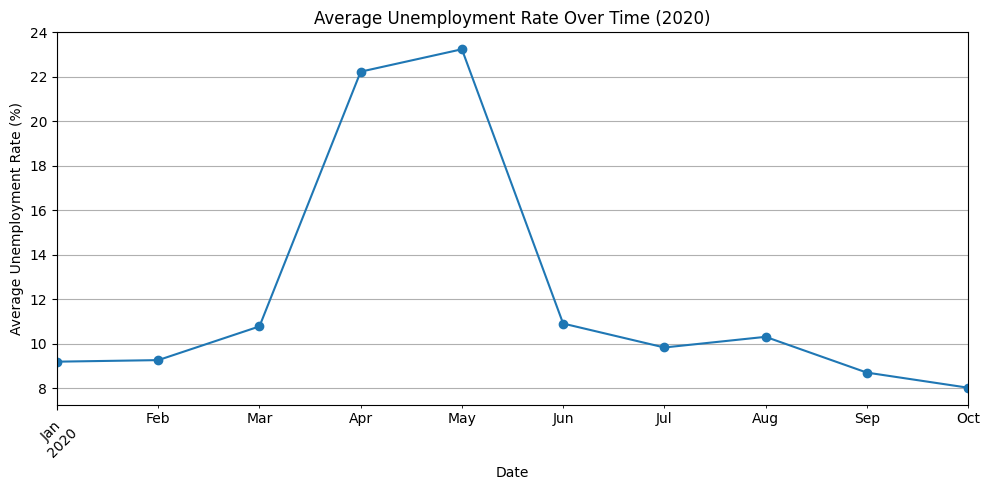

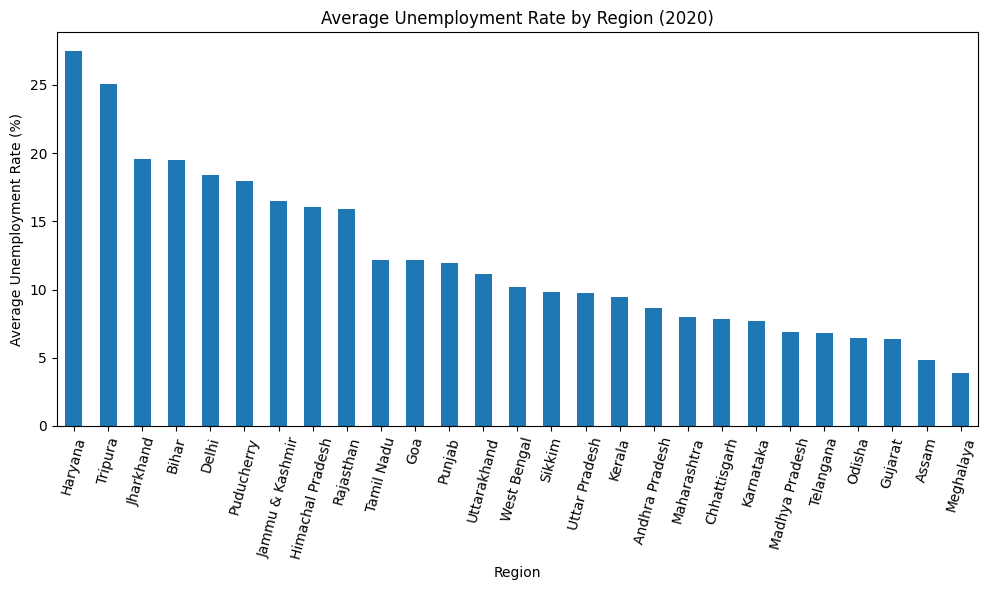

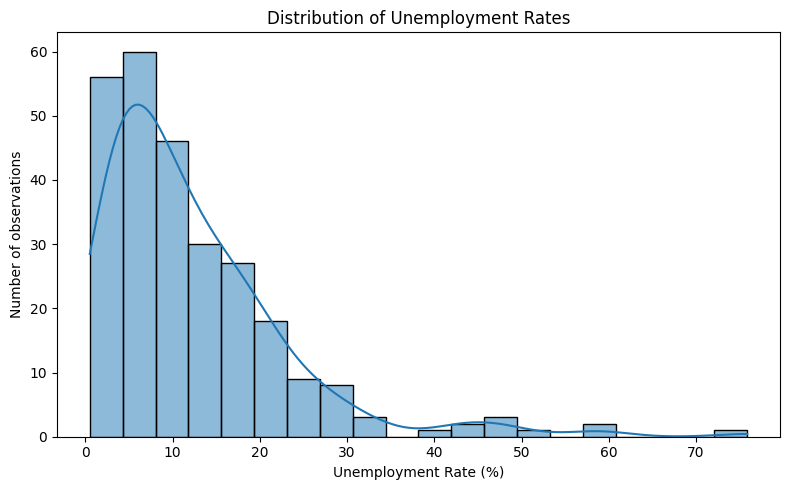

Average unemployment rate: 12.24 %
Highest unemployment rate: 75.85 %
Lowest unemployment rate: 0.5 %

Regions with the highest average unemployment:
Region
Haryana      27.477
Tripura      25.055
Jharkhand    19.539
Bihar        19.471
Delhi        18.414
Name: Unemployment_Rate, dtype: float64


In [4]:

# Step 3: Exploratory Data Analysis and Visualization

# Make sure dates are in chronological order
df = df.sort_values("Date")

# 1. Overall unemployment rate over time
monthly_unemployment = df.groupby("Date")["Unemployment_Rate"].mean()

plt.figure(figsize=(10, 5))
monthly_unemployment.plot(marker="o")
plt.title("Average Unemployment Rate Over Time (2020)")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# 2. Average unemployment rate by region
regional_unemployment = (
    df.groupby("Region")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
regional_unemployment.plot(kind="bar")
plt.title("Average Unemployment Rate by Region (2020)")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


# 3. Unemployment rate distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Unemployment_Rate"], bins=20, kde=True)
plt.title("Distribution of Unemployment Rates")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()


# Display key statistics
print("Average unemployment rate:",
      round(df["Unemployment_Rate"].mean(), 2), "%")

print("Highest unemployment rate:",
      round(df["Unemployment_Rate"].max(), 2), "%")

print("Lowest unemployment rate:",
      round(df["Unemployment_Rate"].min(), 2), "%")

print("\nRegions with the highest average unemployment:")
print(regional_unemployment.head())


## Conclusion

This project analyzed unemployment trends across different regions using Python. The dataset covers the period from January to October 2020 and contains 267 observations.

The overall average unemployment rate was 12.24%, while the highest and lowest recorded rates were 75.85% and 0.5%, respectively. Among the regions analyzed, Haryana had the highest average unemployment rate (27.477%), followed by Tripura (25.055%).

The analysis demonstrates how data cleaning, exploratory data analysis, and data visualization can help identify patterns and differences in unemployment rates across regions.

**Tools used:** Python, Pandas, Matplotlib, and Seaborn.
